In [1]:
!git clone https://github.com/klopotuk1136/BLfS.git

Cloning into 'BLfS'...
remote: Enumerating objects: 113, done.
remote: Counting objects: 100% (113/113), done.
remote: Compressing objects: 100% (83/83), done.
remote: Total 113 (delta 51), reused 65 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (113/113), 106.39 KiB | 864.00 KiB/s, done.
Resolving deltas: 100% (51/51), done.


In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
WORK = '/content/drive/MyDrive/UniVie/Data Mining/a1'
os.makedirs(WORK, exist_ok=True)
print(WORK)

Mounted at /content/drive
/content/drive/MyDrive/UniVie/Data Mining/a1


In [3]:
%cd BLfS
!pip -q install regex einops jaxtyping pytest

/content/BLfS
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 4.2 MB/s eta 0:00:00


In [4]:
import torch
print(torch.__version__, torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no GPU')

2.11.0+cu130 Tesla T4


In [5]:
!python -m pytest -q tests/

........................................................................ [ 97%]
..                                                                       [100%]


In [6]:
%cd /content/BLfS
!pip -q install einops jaxtyping
import os, sys, json, time, shlex, shutil, subprocess
os.environ['PYTHONPATH'] = '/content/BLfS'
WORK = '/content/drive/MyDrive/UniVie/Data Mining/a1'
!python -c "import lm.tokenizer, lm.model, lm.training; print('lm OK')"

/content/BLfS
lm OK


In [7]:
for f in ['tok/vocab.pkl', 'tok/merges.pkl', 'tinystories_valid.txt']:
    assert os.path.exists(f'{WORK}/{f}'), f'missing {WORK}/{f}'

if not os.path.exists(f'{WORK}/val.bin'):
    !python scripts/prepare_data.py --vocab "{WORK}/tok/vocab.pkl" --merges "{WORK}/tok/merges.pkl" --input "{WORK}/tinystories_valid.txt" --output "{WORK}/val.bin"

if not os.path.exists(f'{WORK}/train.bin'):
    if not os.path.exists('/content/raw/tinystories_train.txt'):
        !mkdir -p /content/raw && unzip -o -q "{WORK}/tinystories_train.zip" -d /content/raw
    !python scripts/prepare_data.py --vocab "{WORK}/tok/vocab.pkl" --merges "{WORK}/tok/merges.pkl" --input /content/raw/tinystories_train.txt --output /content/train.bin && cp /content/train.bin "{WORK}/train.bin"

!mkdir -p /content/data && cp "{WORK}/train.bin" "{WORK}/val.bin" /content/data/ && ls -la /content/data

total 1066924
drwxr-xr-x 2 root root       4096 Oct 21 08:31 .
drwxr-xr-x 1 root root       4096 Oct 21 08:31 ..
-rw------- 1 root root 1081593556 Oct 21 08:31 train.bin
-rw------- 1 root root   10922420 Oct 21 08:31 val.bin


In [14]:
import numpy as np, torch, matplotlib.pyplot as plt
from lm.model import TransformerLM
from lm.training import AdamW, cross_entropy, clip_grad_norm_, get_batch

device = 'cuda'
CFG = dict(vocab_size=10000, context_length=256, d_model=512, num_layers=4, num_heads=16, d_ff=1344, rope_theta=10000.0)
train = np.memmap('/content/data/train.bin', dtype=np.uint16, mode='r')
os.makedirs(f'{WORK}/checks', exist_ok=True)
print(f'{len(train):,} train tokens |', torch.cuda.get_device_name(0))

540,796,778 train tokens | Tesla T4


## Overfit one batch

step    0  loss 9.2610  gnorm 1.264  1s
step   25  loss 1.6047  gnorm 0.534  12s
loss < 0.1 at step 43
final loss 0.09005799144506454 | all grad norms finite: True


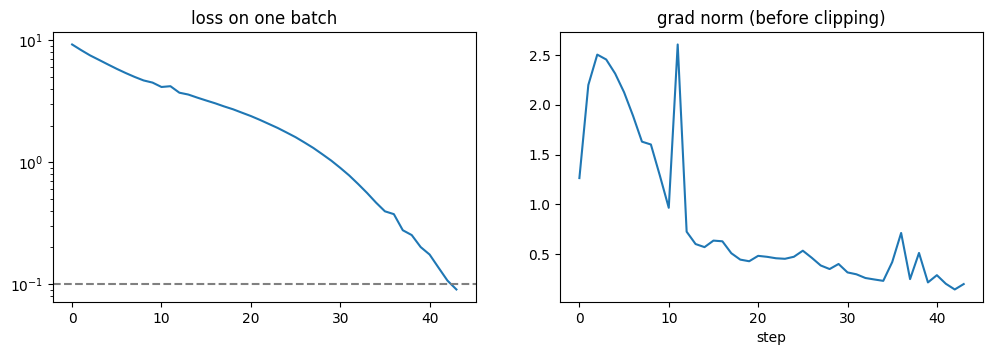

In [ ]:
torch.manual_seed(0); np.random.seed(0)
model = TransformerLM(**CFG).to(device)
opt = AdamW(model.parameters(), lr=1e-3, betas=(0.9, 0.95), weight_decay=0.1)
x, y = get_batch(train, 32, CFG['context_length'], device)

losses, gnorms, t0 = [], [], time.time()
for step in range(500):
    loss = cross_entropy(model(x), y)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    gn = clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    losses.append(loss.item())
    gnorms.append(float(gn))

    if step % 25 == 0:
        print(f'step {step:4d}  loss {losses[-1]:.4f}  gnorm {gnorms[-1]:.3f}  {time.time()-t0:.0f}s')
    if losses[-1] < 0.1:
        print(f'loss < 0.1 at step {step}'); break

print('final loss', losses[-1], '| all grad norms finite:', bool(np.isfinite(gnorms).all()))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(losses)
ax[0].set_yscale('log')
ax[0].axhline(0.1, ls='--', c='gray')
ax[0].set_title('loss on one batch')

ax[1].plot(gnorms)
ax[1].set_title('grad norm (before clipping)')
ax[1].set_xlabel('step')

plt.show()

del model, opt; torch.cuda.empty_cache()

## One profiled step

In [ ]:
from torch.profiler import profile, ProfilerActivity, record_function
torch.manual_seed(0)
model = TransformerLM(**CFG).to(device)
opt = AdamW(model.parameters(), lr=1e-3)
scaler = torch.amp.GradScaler('cuda')
x, y = get_batch(train, 32, CFG['context_length'], device)

def train_step():
    with record_function('## forward'):
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(x)
        loss = cross_entropy(logits.float(), y)
    with record_function('## backward'):
        scaler.scale(loss).backward()
    with record_function('## clip'):
        scaler.unscale_(opt); clip_grad_norm_(model.parameters(), 1.0)
    with record_function('## optimizer'):
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)

for _ in range(5):
    train_step()
torch.cuda.synchronize()
with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as prof:
    train_step()
    torch.cuda.synchronize()
print(prof.key_averages().table(sort_by='cuda_time_total', row_limit=25))
del model, opt; torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                             ## forward         0.00%       0.000us         0.00%       0.000us       0.000us     102.154ms        40.11%     102.154ms     102.154ms             1  
                                             ## forward         3.09%      15.871ms        18.98%      97.623ms      97.623ms       0.000us         0.00%      74.723ms      74.723ms             1  
         

## Stop and recover from save

killed after step 250
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
resumed at step 200
{"step": 200, "loss": 2.8152756690979004, "lr": 0.0005871607054625496, "gnorm": 0.4523061513900757, "tokens_per_s": 9142.78995796839}
{"step": 200, "val_loss": 2.898118317127228}
{"step": 250, "loss": 2.849850654602051, "lr": 0.00040388523885789244, "gnorm": 0.4108109474182129, "tokens_per_s": 12928.194800095796}
{"step": 300, "loss": 2.6344621181488037, "lr": 0.0002452232927684166, "gnorm": 0.41663411259651184, "tokens_per_s": 13312.3720906838}
{"step": 300, "val_loss": 2.7098602950572968}
{"step": 350, "loss": 2.5536952018737793, "lr": 0.00013790200300522413, "gnorm": 0.40354064106941223, "tokens_per_s": 13153.14519293572}
{"step": 399, "val_loss": 2.6420094668865204}
{"lr": 0.001, "steps": 400, "tokens": 3276800, "flops": 366092274892800, "val_loss": 2.6420094668865204, "tokens_per_s": 13061.191441946463, "mfu": 0.022449675517355352, "wallclock_s"

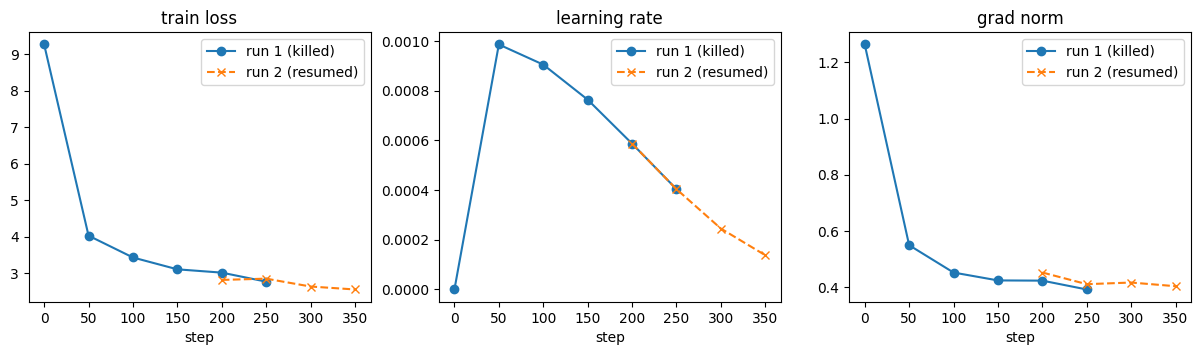

In [ ]:
OUT = f'{WORK}/runs/resume_test'
shutil.rmtree(OUT, ignore_errors=True)
ARGS = ['--data', '/content/data/train.bin', '--val', '/content/data/val.bin', '--out', OUT,
        '--steps', '400', '--eval_every', '100', '--ckpt_every', '100', '--eval_tokens', '65536']
KILL_AT = 250

def read_log():
    p = f'{OUT}/log.jsonl'
    return [json.loads(l) for l in open(p) if l.strip()] if os.path.exists(p) else []

# run 1
p = subprocess.Popen([sys.executable, 'scripts/train.py', *ARGS], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
while p.poll() is None:
    if any('loss' in r and r['step'] >= KILL_AT for r in read_log()):
        p.kill()
        p.wait()
        print(f'killed after step {KILL_AT}')
        break
    time.sleep(2)
assert p.returncode != 0, 'run 1 finished before it was killed'

# run 2
!python scripts/train.py {shlex.join(ARGS)} --resume 2>&1 | grep -vi warning

recs = [r for r in read_log() if 'loss' in r]
cut = next(i for i in range(1, len(recs)) if recs[i]['step'] <= recs[i-1]['step'])
run1, run2 = recs[:cut], recs[cut:]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for run, lab, st in ((run1, 'run 1 (killed)', 'o-'), (run2, 'run 2 (resumed)', 'x--')):
    s = [r['step'] for r in run]
    ax[0].plot(s, [r['loss'] for r in run], st, label=lab)
    ax[1].plot(s, [r['lr'] for r in run], st, label=lab)
    ax[2].plot(s, [r['gnorm'] for r in run], st, label=lab)
for a, t in zip(ax, ('train loss', 'learning rate', 'grad norm')):
    a.set_title(t)
    a.set_xlabel('step')
    a.legend()
plt.show()

## Sweep

In [ ]:
SWEEP = [3e-4, 1e-3, 3e-3, 1e-2]
DATA = ['--data', '/content/data/train.bin', '--val', '/content/data/val.bin']
run_dir = lambda name: f'{WORK}/runs/{name}'

for lr in SWEEP:
    out = run_dir(f'sweep_lr{lr:g}')
    if os.path.exists(f'{out}/summary.json'):
        print('done:', out); continue
    print(f'=== lr_max = {lr:g} ===')
    !python scripts/train.py {shlex.join(DATA + ['--out', out, '--lr_max', str(lr), '--steps', '4883'])} --resume 2>&1 | grep -vi warning

=== lr_max = 0.0003 ===
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
{"step": 0, "loss": 9.260967254638672, "lr": 0.0, "gnorm": 1.2639518976211548, "tokens_per_s": 9103.06045527306}
{"step": 0, "val_loss": 9.255162596702576}
{"step": 50, "loss": 7.7993292808532715, "lr": 6.147540983606557e-05, "gnorm": 2.33052396774292, "tokens_per_s": 13722.57401889967}
{"step": 100, "loss": 5.492882251739502, "lr": 0.00012295081967213115, "gnorm": 1.182325005531311, "tokens_per_s": 19046.80295959306}
{"step": 150, "loss": 4.28181266784668, "lr": 0.00018442622950819672, "gnorm": 0.4314802885055542, "tokens_per_s": 21915.686756304764}
{"step": 200, "loss": 3.8757238388061523, "lr": 0.0002459016393442623, "gnorm": 0.5353055596351624, "tokens_per_s": 23691.85686977779}
{"step": 250, "loss": 3.4427294731140137, "lr": 0.0002999988855600389, "gnorm": 0.5986981987953186, "tokens_per_s": 24889.15413240243}
{"step": 300, "loss": 3.2089316844940186, "lr": 0.000

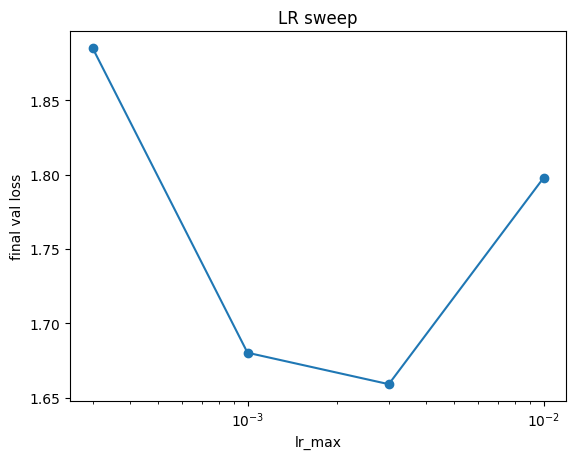

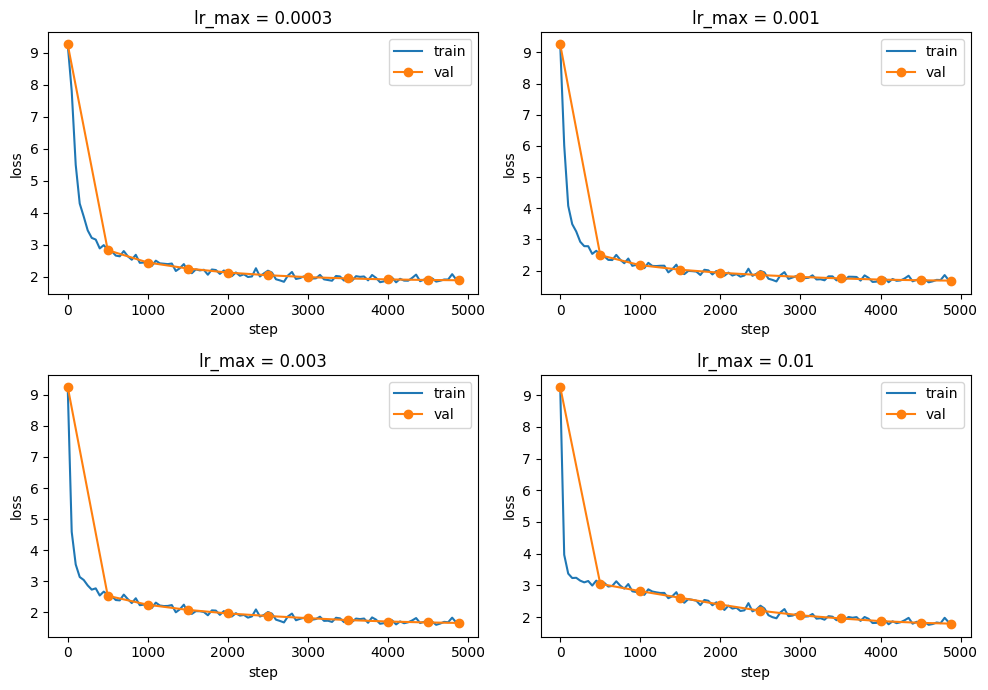

In [11]:
import json, matplotlib.pyplot as plt

SWEEP = [3e-4, 1e-3, 3e-3, 1e-2]
runs = f'{WORK}/runs'

val_losses = [json.load(open(f'{runs}/sweep_lr{lr:g}/summary.json'))['val_loss'] for lr in SWEEP]
plt.plot(SWEEP, val_losses, 'o-')
plt.xscale('log')
plt.xlabel('lr_max')
plt.ylabel('final val loss')
plt.title('LR sweep')
plt.savefig(f'{WORK}/lr_sweep.png')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for lr, ax in zip(SWEEP, axes.flat):
    log = [json.loads(line) for line in open(f'{runs}/sweep_lr{lr:g}/log.jsonl')]
    train = [r for r in log if 'loss' in r]
    val = [r for r in log if 'val_loss' in r]
    ax.plot([r['step'] for r in train], [r['loss'] for r in train], label='train')
    ax.plot([r['step'] for r in val], [r['val_loss'] for r in val], 'o-', label='val')
    ax.set_title(f'lr_max = {lr:g}')
    ax.set_xlabel('step')
    ax.set_ylabel('loss')
    ax.legend()
plt.tight_layout()
plt.savefig(f'{WORK}/lr_sweep_curves.png')
plt.show()

## The best run

In [ ]:
import math
sweep = {lr: json.load(open(f"{run_dir(f'sweep_lr{lr:g}')}/summary.json"))['val_loss'] for lr in SWEEP}
print(sweep)
BEST_LR = min((lr for lr in sweep if math.isfinite(sweep[lr])), key=sweep.get)
print('best lr_max:', BEST_LR)

out = run_dir('ref')
!python scripts/train.py {shlex.join(DATA + ['--out', out, '--lr_max', str(BEST_LR)])} --resume 2>&1 | grep -vi warning
print(json.load(open(f'{out}/summary.json')))

{0.0003: 1.8848333898931742, 0.001: 1.680309671908617, 0.003: 1.659185953438282, 0.01: 1.7977770045399666}
best lr_max: 0.003
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
{"step": 0, "loss": 9.260967254638672, "lr": 0.0, "gnorm": 1.2639518976211548, "tokens_per_s": 12776.580441940672}
{"step": 0, "val_loss": 9.255162596702576}
{"step": 50, "loss": 6.910175323486328, "lr": 0.00012295081967213115, "gnorm": 2.1796607971191406, "tokens_per_s": 13598.889798658132}
{"step": 100, "loss": 4.541109085083008, "lr": 0.0002459016393442623, "gnorm": 0.44005608558654785, "tokens_per_s": 18869.41297514793}
{"step": 150, "loss": 3.739567518234253, "lr": 0.00036885245901639344, "gnorm": 0.4252994954586029, "tokens_per_s": 21682.03606535423}
{"step": 200, "loss": 3.473642349243164, "lr": 0.0004918032786885246, "gnorm": 0.4797893762588501, "tokens_per_s": 23416.862570896345}
{"step": 250, "loss": 3.103503704071045, "lr": 0.0006147540983606558, "gnorm": 0

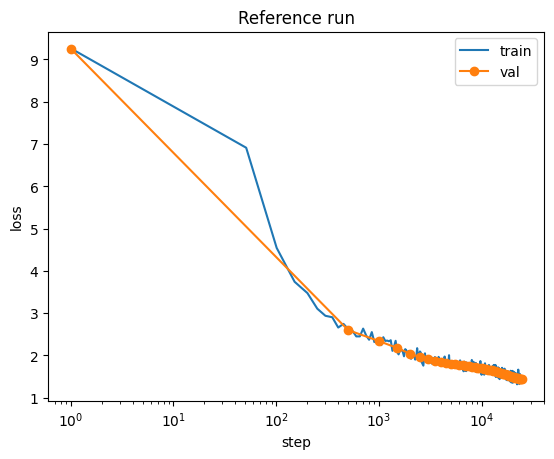

final val loss: 1.4430
GPU: Tesla T4
tokens/s: 26,773
MFU: 4.6%


In [12]:
import json, matplotlib.pyplot as plt

ref = f'{WORK}/runs/ref'
log = [json.loads(line) for line in open(f'{ref}/log.jsonl')]
summary = json.load(open(f'{ref}/summary.json'))

train = [r for r in log if 'loss' in r]
val = [r for r in log if 'val_loss' in r]

plt.plot([r['step'] + 1 for r in train], [r['loss'] for r in train], label='train')
plt.plot([r['step'] + 1 for r in val], [r['val_loss'] for r in val], 'o-', label='val')
plt.xscale('log')
plt.xlabel('step')
plt.ylabel('loss')
plt.title('Reference run')
plt.legend()
plt.savefig(f'{WORK}/ref_curves.png')
plt.show()

print(f"final val loss: {summary['val_loss']:.4f}")
print(f"GPU: {summary['gpu']}")
print(f"tokens/s: {summary['tokens_per_s']:,.0f}")
print(f"MFU: {summary['mfu']:.1%}")

## Efficiency table

In [15]:
import time, torch, torch.nn.functional as F
import lm.model
from lm.model import TransformerLM, count_flops
from lm.training import AdamW, cross_entropy, clip_grad_norm_, get_batch

CFG = dict(vocab_size=10000, context_length=256, d_model=512, num_layers=4, num_heads=16, d_ff=1344)
_, TRAIN_FLOPS = count_flops(**CFG, seq_len=256)
PEAK = {'T4': 65e12, 'L4': 121e12, 'A100': 312e12}
peak = next(v for k, v in PEAK.items() if k in torch.cuda.get_device_name(0))
amp_dtype = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16

my_sdpa = lm.model.scaled_dot_product_attention
torch_sdpa = lambda q, k, v, mask=None: F.scaled_dot_product_attention(q, k, v, is_causal=True)

def benchmark(amp, torch_attention, fused_adamw, compiled):
    lm.model.scaled_dot_product_attention = torch_sdpa if torch_attention else my_sdpa
    model = TransformerLM(**CFG).to(device)
    if fused_adamw:
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, betas=(0.9, 0.95), weight_decay=0.1, fused=True)
    else:
        opt = AdamW(model.parameters(), lr=1e-3, betas=(0.9, 0.95), weight_decay=0.1)
    forward = torch.compile(model) if compiled else model
    scaler = torch.amp.GradScaler('cuda', enabled=amp and amp_dtype == torch.float16)

    def step():
        x, y = get_batch(train, 32, 256, device)
        with torch.autocast('cuda', dtype=amp_dtype, enabled=amp):
            logits = forward(x)
        loss = cross_entropy(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)

    for _ in range(20):
        step()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(200):
        step()
    torch.cuda.synchronize()
    tokens_per_s = 200 * 32 * 256 / (time.perf_counter() - t0)

    lm.model.scaled_dot_product_attention = my_sdpa
    return tokens_per_s

configs = [
    ('eager fp32',              dict(amp=False, torch_attention=False, fused_adamw=False, compiled=False)),
    ('+ autocast',              dict(amp=True,  torch_attention=False, fused_adamw=False, compiled=False)),
    ('+ F.sdpa',                dict(amp=True,  torch_attention=True,  fused_adamw=False, compiled=False)),
    ('+ fused AdamW',           dict(amp=True,  torch_attention=True,  fused_adamw=True,  compiled=False)),
    ('+ torch.compile',         dict(amp=True,  torch_attention=True,  fused_adamw=True,  compiled=True)),
]

efficiency = []
for name, kw in configs:
    tps = benchmark(**kw)
    mfu = tps * TRAIN_FLOPS / peak
    efficiency.append({'config': name, 'tokens_per_s': round(tps), 'mfu': round(mfu, 4)})
    print(f'{name:18s} {tps:10,.0f} tokens/s   MFU {mfu:.1%}')

import pandas as pd
pd.DataFrame(efficiency).to_csv(f'{WORK}/efficiency.csv', index=False)

eager fp32             19,268 tokens/s   MFU 3.3%
+ autocast             31,037 tokens/s   MFU 5.3%
+ F.sdpa               53,745 tokens/s   MFU 9.2%
+ fused AdamW          57,160 tokens/s   MFU 9.8%


W1021 09:27:47.328000 605 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


+ torch.compile        84,260 tokens/s   MFU 14.5%


## Ablation

In [ ]:
out = run_dir('abl_no_warmup')
!python scripts/train.py {shlex.join(DATA + ['--out', out, '--lr_max', str(BEST_LR), '--steps', '4883', '--warmup_frac', '0'])} --resume 2>&1 | grep -vi warning
print('baseline', sweep[BEST_LR], '| no warmup', json.load(open(f'{out}/summary.json'))['val_loss'])

  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
{"step": 0, "loss": 9.260967254638672, "lr": 0.003, "gnorm": 1.2639518976211548, "tokens_per_s": 12433.59352695534}
{"step": 0, "val_loss": 8.214478060603142}
{"step": 50, "loss": 4.080531597137451, "lr": 0.002999301554334516, "gnorm": 0.4663054049015045, "tokens_per_s": 13963.23654733598}
{"step": 100, "loss": 3.5978002548217773, "lr": 0.002997206940043765, "gnorm": 0.46404069662094116, "tokens_per_s": 19320.15811749915}
{"step": 150, "loss": 3.3226888179779053, "lr": 0.0029937183244970393, "gnorm": 0.36303022503852844, "tokens_per_s": 22178.82867113822}
{"step": 200, "loss": 3.2048897743225098, "lr": 0.002988839317484571, "gnorm": 0.36435025930404663, "tokens_per_s": 23938.609482173455}
{"step": 250, "loss": 2.96160626411438, "lr": 0.00298257496748236, "gnorm": 0.39301759004592896, "tokens_per_s": 25117.564715168584}
{"step": 300, "loss": 2.866464138031006, "lr": 0.002974931756428341, "gno

## Samples

In [10]:
import json, torch
from lm.model import TransformerLM
from lm.tokenizer import Tokenizer
from lm.training import generate

device = 'cuda' if torch.cuda.is_available() else 'cpu'
ref_dir = f'{WORK}/runs/ref'
cfg = json.load(open(f'{ref_dir}/config.json'))

model = TransformerLM(cfg['vocab_size'], cfg['context_length'], cfg['d_model'], cfg['num_layers'],
                      cfg['num_heads'], cfg['d_ff'], cfg['rope_theta']).to(device)
ckpt = torch.load(f'{ref_dir}/ckpt.pt', map_location=device)
model.load_state_dict(ckpt['model'])
model.eval()
print('loaded checkpoint at step', ckpt['step'])

tok = Tokenizer.from_files(f'{WORK}/tok/vocab.pkl', f'{WORK}/tok/merges.pkl', ['<|endoftext|>'])

PROMPTS = [
    'On a dark rainy day',
    'In a far far away land, a knight named Shrek lived.',
    "Dogs don't like cats because",
    'Tom and Jerry were a regular cat and a mice.',
    'My mom once told me this story:',
]
SETTINGS = [(p, 0.7, 0.9, i) for i, p in enumerate(PROMPTS)] + [(PROMPTS[0], 1.5, 0.9, 99)]

samples = []
for prompt, temperature, top_p, seed in SETTINGS:
    text = generate(model, tok, prompt, max_new_tokens=256, temperature=temperature, top_p=top_p, seed=seed)
    n_tokens = len(tok.encode(text))
    samples.append(dict(prompt=prompt, temperature=temperature, top_p=top_p, seed=seed, text=text))
    print(f'=== T={temperature}, p={top_p}, {n_tokens} new tokens ===')
    print(prompt + text, '\n')

json.dump(samples, open(f'{WORK}/samples.json', 'w'), indent=2, ensure_ascii=False)
print('saved', len(samples), 'samples to', f'{WORK}/samples.json')

loaded checkpoint at step 24414
=== T=0.7, p=0.9, 139 new tokens ===
On a dark rainy day, a little boy named Tim went to the park with his mom. They saw a big tree with a swing. Tim loved to swing high in the sky.
Tim's mom said, "Tim, let's swing on the tree!" Tim said, "Yes, Mom, I like the tree!" They both took turns on the swing. Tim swung high and laughed as he went up and down.
As they were swinging, Tim saw a girl named Sue. Sue had a big, shiny toy car too. Tim and Sue both wanted the toy car. They were sad and decided to share the toy car. They took turns playing with the toy car and had lots of fun.
 

=== T=0.7, p=0.9, 204 new tokens ===
In a far far away land, a knight named Shrek lived. Shok loved to find new things. One day, he found a big, shiny rock. He was very happy and wanted to show it to his friend, Cat.
"Look, Cat!" said Shok. "I found a big rock!" Cat looked at the rock and said, "Wow, it's so big! Let's keep it safe." So, Shok and Cat went to find more rocks to 

## Results

In [16]:
import json, time
import pandas as pd
from lm.tokenizer import Tokenizer
from lm.model import count_params, count_flops

# ---- fill in by hand
TOKENIZER_TRAIN_SECONDS = 0       # "whole train: ... s" from train_tokenizer.py
TOKENIZER_PEAK_MEMORY_GB = 0.0    # "peak memory: ... GB" from train_tokenizer.py
ABLATION_NAME = 'no_warmup'
PREDICTED_DELTA = 0.0             # your prediction, written down before the ablation run

runs = f'{WORK}/runs'
def load(path):
    return json.load(open(path))

# ---- tokenizer
tok = Tokenizer.from_files(f'{WORK}/tok/vocab.pkl', f'{WORK}/tok/merges.pkl', ['<|endoftext|>'])

def bytes_per_token(path):
    text = open(path, encoding='utf-8').read(5_000_000)     # first ~5 MB
    return len(text.encode('utf-8')) / len(tok.encode(text))

owt_text = open(f'{WORK}/owt_valid.txt', encoding='utf-8').read(5_000_000)
tok.cache.clear()
t0 = time.perf_counter()
tok.encode(owt_text)
encode_mb_per_s = len(owt_text.encode('utf-8')) / 1e6 / (time.perf_counter() - t0)

tokenizer = {
    'vocab_size': len(tok.vocab),
    'train_seconds': TOKENIZER_TRAIN_SECONDS,
    'peak_memory_gb': TOKENIZER_PEAK_MEMORY_GB,
    'encode_mb_per_s': round(encode_mb_per_s, 2),
    'bytes_per_token': {
        'tinystories_val': round(bytes_per_token(f'{WORK}/tinystories_valid.txt'), 2),
        'owt_sample': round(bytes_per_token(f'{WORK}/owt_valid.txt'), 2),
    },
    'longest_token': max(tok.vocab.values(), key=len).decode('utf-8', errors='replace'),
}

CFG = dict(vocab_size=10000, context_length=256, d_model=512, num_layers=4, num_heads=16, d_ff=1344)
model = {'params': count_params(**CFG), 'flops_per_token_fwd': count_flops(**CFG, seq_len=256)[0]}

lr_sweep = []
for lr in [3e-4, 1e-3, 3e-3, 1e-2]:
    s = load(f'{runs}/sweep_lr{lr:g}/summary.json')
    lr_sweep.append({'lr': lr, 'steps': s['steps'], 'val_loss': s['val_loss']})

ref = load(f'{runs}/ref/summary.json')
reference_run = {k: ref[k] for k in ['lr', 'steps', 'tokens', 'flops', 'val_loss', 'tokens_per_s', 'mfu', 'wallclock_s']}

efficiency = pd.read_csv(f'{WORK}/efficiency.csv').to_dict('records')

abl = load(f'{runs}/abl_{ABLATION_NAME}/summary.json')
base = load(f"{runs}/sweep_lr{abl['lr']:g}/summary.json")
ablation = {'name': ABLATION_NAME, 'predicted_delta': PREDICTED_DELTA,
            'measured_delta': round(abl['val_loss'] - base['val_loss'], 4)}

samples = [s['prompt'] + s['text'] for s in load(f'{WORK}/samples.json')]

results = {
    'tokenizer': tokenizer,
    'model': model,
    'gpu': ref['gpu'],
    'precision': {'float16': 'fp16', 'bfloat16': 'bf16'}.get(ref['precision'], ref['precision']),
    'lr_sweep': lr_sweep,
    'reference_run': reference_run,
    'efficiency': efficiency,
    'ablation': ablation,
    'samples': samples,
}
json.dump(results, open(f'{WORK}/results.json', 'w'), indent=2, ensure_ascii=False)
print(json.dumps({k: v for k, v in results.items() if k != 'samples'}, indent=2))

{
  "tokenizer": {
    "vocab_size": 10000,
    "train_seconds": 0,
    "peak_memory_gb": 0.0,
    "encode_mb_per_s": 2.01,
    "bytes_per_token": {
      "tinystories_val": 4.12,
      "owt_sample": 3.22
    },
    "longest_token": " accomplishment"
  },
  "model": {
    "params": 22696448,
    "flops_per_token_fwd": 37240832
  },
  "gpu": "Tesla T4",
  "precision": "fp16",
  "lr_sweep": [
    {
      "lr": 0.0003,
      "steps": 4883,
      "val_loss": 1.8848333898931742
    },
    {
      "lr": 0.001,
      "steps": 4883,
      "val_loss": 1.680309671908617
    },
    {
      "lr": 0.003,
      "steps": 4883,
      "val_loss": 1.659185953438282
    },
    {
      "lr": 0.01,
      "steps": 4883,
      "val_loss": 1.7977770045399666
    }
  ],
  "reference_run": {
    "lr": 0.003,
    "steps": 24414,
    "tokens": 199999488,
    "flops": 22344441998082048,
    "val_loss": 1.4429823514074087,
    "tokens_per_s": 26772.81468563462,
    "mfu": 0.04601731817883931,
    "wallclock_s": 747